# Logic Tensor Networks — Learning Concept Embeddings from a Knowledge Base

**Guiding question.** Can a neural model learn *where concepts live* in a latent space and *which relations hold* between them, using a sparse collection of facts together with logical rules?

We will build a tiny animal ontology with two learnable predicates, $IsA(x,y)$ and $HasProperty(x,p)$, and a distance-based predicate $Similar(x,y)$. The model learns **concept embeddings**, **property representations**, and **neural predicate parameters** jointly. Logical knowledge influences all of them through gradients.

### The three parts of the model

1. **Ground individuals/concepts as vectors.** Each ontology node, such as `Dog` or `Mammal`, gets a trainable $e_c\in\mathbb R^2$. Each property gets a learnable direction $v_p\in\mathbb R^2$ and bias $b_p$. The two dimensions are *features of one concept*, not two different individuals.
2. **Ground predicates as differentiable functions.** $IsA_\theta(e_x,e_y)\in[0,1]$ is a neural network. $HasProperty(x,p)=\sigma(3(e_x^\top v_p+b_p))$ uses a dot product. $Similar(x,y)=\exp(-\|e_x-e_y\|^2/(2\sigma_{geo}^2))$ encodes proximity.
3. **Ground formulas with fuzzy logic.** Facts such as $IsA(Dog,Mammal)$ supply labels, while general rules such as transitivity penalize *inconsistent relations*. **LTNtorch** supplies predicates, logical connectives, and variable handling. PyTorch optimizes the resulting differentiable training objective.

### What do the logical variables represent?

A logical variable $x$ ranges over **concepts**, not over coordinates of one embedding. If $x$ ranges over $N$ concepts with $d=2$ features each, its grounded tensor has shape $(N,2)$. The predicate $IsA(x,y)$ maps a pair of concept embeddings to **one** fuzzy truth degree. During training, we evaluate specific observed pairs or rule-grounding triples.

### What information is available during training?

Some positive/negative facts are observed, while other facts are deliberately hidden. We know, for example, $IsA(Dog,Mammal)$ and $IsA(Mammal,Animal)$ but hold out $IsA(Dog,Animal)$. The latter can follow from **transitivity**. Likewise, $HasProperty(Mammal,BreathesAir)$ and $IsA(Dog,Mammal)$ support the withheld property $HasProperty(Dog,BreathesAir)$ through **inheritance**.

The absence of a fact is **not** treated as a negative label. We supply negative observations explicitly.

### Three controlled experiments — same supervised facts and initialization

| Experiment | Observed facts | Transitivity + inheritance | Derived geometric constraints |
|---|:---:|:---:|:---:|
| **Facts only** | Yes | No | No |
| **Facts + logic** | Yes | Yes | No |
| **Facts + logic + geometry** | Yes | Yes | Yes |

Crucially, the third experiment receives **no labeled `Similar` pairs**. It constructs a proximity *inductive bias* from the existing taxonomy: concepts sharing an informative parent (`Mammal`, `Bird`, `Fish`) should be close; concepts in disjoint families should be separated. The family-disjointness assumption is explicit domain knowledge; it is not inferred merely from the absence of an `IsA` edge.

We compare: (i) truth degrees on *withheld logical conclusions*, (ii) rule violations, and (iii) actual 2D embedding geometry. **Logical consistency alone does not guarantee geometric clustering**: a sufficiently expressive predicate could learn correct relations even if its concept vectors are not visually grouped.

> **Learning objective.** We use supervised binary cross-entropy for observed facts and a generalized-mean-error penalty for the fuzzy rule groundings. These are different roles: strong grounding to the data, plus differentiable logical regularization. Everything is trained jointly.

## 0 · Dependencies and reproducibility

Run the installation command in the next cell if needed. LTNtorch provides the fuzzy connective implementations; PyTorch stores and updates all learnable embeddings and neural weights. A fixed seed and a shared initial state let us compare the three training objectives fairly.

In [1]:
# Uncomment if the package is not installed in your notebook environment:
# %pip install LTNtorch

import copy, random
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
try:
    import ltn
except ImportError as exc:
    raise ImportError("LTNtorch is required. Run `%pip install LTNtorch` in this notebook, then restart the kernel.") from exc
print('PyTorch:', torch.__version__, '| LTNtorch:', getattr(ltn,'__version__','installed'))

PyTorch: 2.15.0 | LTNtorch: installed


## 1 · Specify a deliberately incomplete knowledge base

We use 11 **concept nodes** and 5 **properties**. The ontology has three informative animal families (`Mammal`, `Bird`, `Fish`), with `Animal` as their general parent.

- `isa_pos` and `has_pos` contain observed true facts.
- `isa_neg` and `has_neg` contain observed false facts. These are not inferred from missing edges.
- `heldout_pos` contains consequences of the observed facts and rules; no held-out label enters the objective.
- `heldout_neg` contains additional negative queries for evaluation. Some are *not* logically implied by the positive rules, so accuracy on them measures generalization rather than formal entailment.

Our property-inheritance rule is a deliberately simple, exception-free teaching assumption; real ontologies may need defeasible properties.

In [2]:
import random, copy
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED=19
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(2)
concepts=['Animal','Mammal','Bird','Fish','Dog','Cat','Whale','Eagle','Penguin','Salmon','Shark']
props=['BreathesAir','HasFur','HasWings','CanFly','CanSwim']
ci={v:i for i,v in enumerate(concepts)}
pi={v:i for i,v in enumerate(props)}
isa_pos=[('Mammal','Animal'),('Bird','Animal'),('Fish','Animal'),
         ('Dog','Mammal'),('Cat','Mammal'),('Whale','Mammal'),
         ('Eagle','Bird'),('Penguin','Bird'),('Salmon','Fish'),('Shark','Fish')]
isa_neg=[('Animal','Dog'),('Animal','Bird'),('Mammal','Dog'),('Bird','Eagle'),
         ('Dog','Bird'),('Cat','Fish'),('Whale','Bird'),('Eagle','Fish'),
         ('Penguin','Mammal'),('Salmon','Bird'),('Shark','Mammal'),('Fish','Mammal')]
# Positive property observations are largely limited to parent categories.
has_pos=[('Mammal','BreathesAir'),('Bird','HasWings'),('Fish','CanSwim'),
         ('Dog','HasFur'),('Cat','HasFur'),('Whale','CanSwim'),
         ('Eagle','CanFly'),('Penguin','CanSwim')]
has_neg=[('Fish','HasFur'),('Fish','BreathesAir'),('Bird','HasFur'),
         ('Dog','CanFly'),('Cat','CanSwim'),('Eagle','HasFur'),
         ('Penguin','CanFly'),('Shark','HasWings'),('Salmon','HasWings')]
# Rule-supported positive test facts, deliberately absent from the supervised set:
heldout_pos=[('IsA','Dog','Animal'),('IsA','Cat','Animal'),('IsA','Whale','Animal'),
             ('IsA','Eagle','Animal'),('IsA','Penguin','Animal'),
             ('IsA','Salmon','Animal'),('IsA','Shark','Animal'),
             ('Has','Dog','BreathesAir'),('Has','Cat','BreathesAir'),
             ('Has','Whale','BreathesAir'),('Has','Eagle','HasWings'),
             ('Has','Penguin','HasWings'),('Has','Salmon','CanSwim'),
             ('Has','Shark','CanSwim')]
# Explicit negative holdouts: these cannot be concluded from a missing edge.
# They are only used for evaluation, not as additional logical training premises.
heldout_neg=[('IsA','Dog','Fish'),('IsA','Eagle','Mammal'),
             ('IsA','Salmon','Mammal'),('Has','Shark','CanFly')]
print(f'{len(concepts)} concepts, {len(props)} properties')
print(f'{len(isa_pos)+len(has_pos)} positive observed facts; {len(heldout_pos)} withheld positive conclusions')

11 concepts, 5 properties
18 positive observed facts; 14 withheld positive conclusions


### Visualize the *observed* concept hierarchy

Edges display the positive `IsA` facts supplied to training. The diagram uses manually selected positions **only to draw the ontology**; these coordinates are never passed to the model. The embeddings we learn later begin from random values.

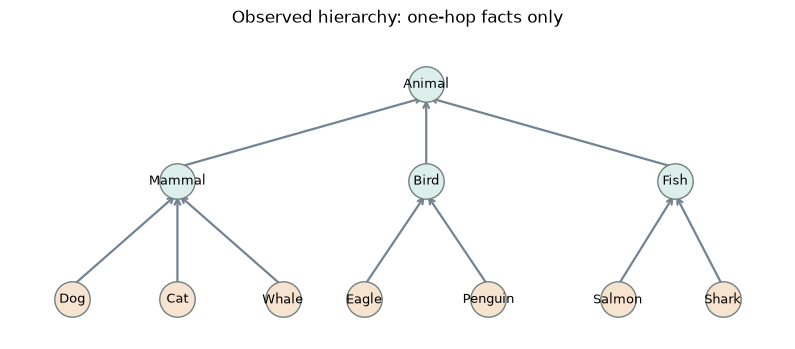

In [3]:
xy={'Animal':(0,3.2),'Mammal':(-2.6,2.1),'Bird':(0,2.1),'Fish':(2.6,2.1),
    'Dog':(-3.7,.75),'Cat':(-2.6,.75),'Whale':(-1.5,.75),
    'Eagle':(-.65,.75),'Penguin':(.65,.75),'Salmon':(2,.75),'Shark':(3.1,.75)}
fig,ax=plt.subplots(figsize=(10,4))
for child,parent in isa_pos:
    ax.annotate('',xy=(xy[parent][0],xy[parent][1]-.15),xytext=(xy[child][0],xy[child][1]+.15),
                arrowprops=dict(arrowstyle='->',color='#748394',lw=1.6))
for name,(x,y) in xy.items():
    ax.scatter(x,y,s=650,c='#dcefeb' if name in ('Animal','Mammal','Bird','Fish') else '#f6e4d0',edgecolors='#738180',zorder=3)
    ax.text(x,y,name,ha='center',va='center',fontsize=9,zorder=4)
ax.set_xlim(-4.35,3.75);ax.set_ylim(.3,3.8);ax.axis('off');ax.set_title('Observed hierarchy: one-hop facts only');plt.show()

## 2 · Learn concept vectors and predicate groundings

Each concept $c$ has a trainable embedding $e_c\in\mathbb R^2$, so the concept-embedding matrix is $(11,2)$. The property matrix has shape $(5,2)$ and the property-bias vector has shape $(5,)$. All of these are PyTorch parameters.

We evaluate the relations with three grounded predicates:

$$IsA_\theta(x,y)=\sigma(MLP_\theta([e_x,e_y]))$$

$$HasProperty(x,p)=\sigma\!\left(3(e_x^\top v_p+b_p)\right)$$

$$Similar(x,y)=\exp\!\left(-\frac{\|e_x-e_y\|_2^2}{2(0.70)^2}\right)$$

- `IsA` learns a general *directed* relation. It need not be symmetric or a Euclidean distance.
- `HasProperty` learns which latent directions support each property. $b_p$ is a baseline logit for property $p$.
- `Similar` has **no neural parameters** of its own: its values change when the concept embeddings change.

None of the embeddings starts with a semantic interpretation. The training signal from facts and rules shapes how the coordinates are used.

In [4]:
class IsAGround(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(4,20),nn.Tanh(),nn.Linear(20,1))
    def forward(self, a, b):
        return torch.sigmoid(self.net(torch.cat([a,b],dim=-1)).squeeze(-1))

class HasGround(nn.Module):
    def forward(self, animal, prop):
        vector, bias = prop[..., :2], prop[..., 2]
        return torch.sigmoid(3.0 * ((animal*vector).sum(-1)+bias))

class SimilarGround(nn.Module):
    def forward(self, a, b):
        return torch.exp(-((a-b)**2).sum(-1)/(2*0.70**2))

class ConceptLTN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb=nn.Embedding(len(concepts),2)
        self.property_vec=nn.Embedding(len(props),2)
        self.property_bias=nn.Parameter(torch.zeros(len(props)))
        self.isa_ground=IsAGround()
        self.has_ground=HasGround()
        self.sim_ground=SimilarGround()
        with torch.no_grad():
            self.emb.weight.normal_(0,0.48)
            self.property_vec.weight.normal_(0,0.45)
    def concept_vectors(self, indices):
        return self.emb(indices)
    def property_vectors(self, indices):
        return torch.cat([self.property_vec(indices),self.property_bias[indices,None]],dim=-1)
    # Convenient direct calls for evaluation, not a replacement for LTN predicates.
    def isa(self,a,b): return self.isa_ground(self.emb(a),self.emb(b))
    def has(self,a,p): return self.has_ground(self.emb(a),self.property_vectors(p))
    def similar(self,a,b): return self.sim_ground(self.emb(a),self.emb(b))

initial_model=ConceptLTN()
initial_weights=copy.deepcopy(initial_model.state_dict())
print('Concept embeddings:',tuple(initial_model.emb.weight.shape))
print('Property vectors:',tuple(initial_model.property_vec.weight.shape))
print('Example truth value:',float(initial_model.has(torch.tensor(ci['Dog']),torch.tensor(pi['HasFur']))))

Concept embeddings: (11, 2)
Property vectors: (5, 2)
Example truth value: 0.45837944746017456


/var/folders/2_/z19rv3zx4s55k528411fsn800000gn/T/ipykernel_71881/3794855368.py:42: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  print('Example truth value:',float(initial_model.has(torch.tensor(ci['Dog']),torch.tensor(pi['HasFur']))))


## 3 · Express the KB with differentiable LTNtorch logic

We use **product conjunction** $T(a,b)=ab$, **Reichenbach implication** $I(a,b)=1-a(1-b)$, and standard negation $\neg a=1-a$. These are smooth (or differentiable almost everywhere) and propagate useful gradients.

Two families of rules matter:

**Taxonomy transitivity**
$$\forall x,y,z:\quad IsA(x,y)\land IsA(y,z)\to IsA(x,z)$$

**Inheritance of properties**
$$\forall x,y,p:\quad IsA(x,y)\land HasProperty(y,p)\to HasProperty(x,p)$$

The notebook trains on a **selected finite grounding** of these universally stated rules, rather than literally iterating over every possible triple. For instance, the groundings of $Dog\to Mammal\to Animal$ and $Dog\to Mammal\to BreathesAir$ produce the withheld conclusions.

**Why a hybrid objective?** A high satisfaction score on a rule does not guarantee that observed labels are strongly fitted: implication can be made true by lowering its antecedent. We therefore use binary cross-entropy to *anchor* facts, and a fuzzy violation penalty to constrain their implications.

For a collection of truth degrees $t_1,\dots,t_n$, the generalized mean error (with $p=2$) is
$$GME_2(t)=\sqrt{\frac1n\sum_{i=1}^n(1-t_i)^2}.$$
This is computed over **individual rule groundings**; we do not aggregate already-quantified truth values a second time.

In [5]:
# Operator choices are now managed by LTNtorch.
And = ltn.Connective(ltn.fuzzy_ops.AndProd())
Implies = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Not = ltn.Connective(ltn.fuzzy_ops.NotStandard())

def pair_tensors(pairs,left,right):
    return (torch.tensor([left[a] for a,b in pairs],dtype=torch.long),
            torch.tensor([right[b] for a,b in pairs],dtype=torch.long))
ip_a,ip_b=pair_tensors(isa_pos,ci,ci)
in_a,in_b=pair_tensors(isa_neg,ci,ci)
hp_a,hp_b=pair_tensors(has_pos,ci,pi)
hn_a,hn_b=pair_tensors(has_neg,ci,pi)
trans=[(a,b,c) for a,b in isa_pos for bb,c in isa_pos if bb==b and (a,c) not in isa_pos]
inherit=[(a,b,p) for a,b in isa_pos for bb,p in has_pos if bb==b and (a,p) not in has_pos]
ta,tb,tc=(torch.tensor([ci[t[k]] for t in trans]) for k in range(3))
ia=torch.tensor([ci[a] for a,b,p in inherit]); ib=torch.tensor([ci[b] for a,b,p in inherit])
ip=torch.tensor([pi[p] for a,b,p in inherit])
print('Selected transitivity instances:',len(trans),'| property inheritance instances:',len(inherit))

Selected transitivity instances: 7 | property inheritance instances: 7


### How do `ltn.Variable` and `ltn.diag` work?

LTNtorch variables contain **collections of complete feature vectors**, not separate feature coordinates. Given $K$ rule-grounding triples, each variable holds a tensor of shape $(K,2)$.

We want *aligned rows*: $(x_i,y_i,z_i)$ for $i=1,\dots,K$, not all $K^3$ combinations. `ltn.diag(x,y,z)` tells LTNtorch to align these assignments. Then `IsA(x,y)` produces a $K$-element truth tensor.

In our implementation, we keep that vector of truth values through the connective and compute its GME penalty. This retains a clear per-grounding loss while using **LTNtorch for predicate evaluation and logical operations**.

In [6]:
def grounded(model, indexes, kinds, prefix):
    """Return aligned variables containing the *current* learned embeddings."""
    variables=[]
    for j,(ids,kind) in enumerate(zip(indexes,kinds)):
        vectors = model.concept_vectors(ids) if kind=='concept' else model.property_vectors(ids)
        variables.append(ltn.Variable(f'{prefix}{j}', vectors))
    return ltn.diag(*variables)

def operators_for(model):
    return (ltn.Predicate(model=model.isa_ground),
            ltn.Predicate(model=model.has_ground),
            ltn.Predicate(model=model.sim_ground))

def gme(truth_values):
    """Generalized mean error, p=2; truth_values is an LTN .value tensor."""
    return torch.sqrt(torch.mean((1.0 - truth_values)**2) + 1e-12)

def fact_loss(model):
    """BCE on explicitly supervised facts; no assumptions about missing facts."""
    IsA, Has, _ = operators_for(model)
    x,y=grounded(model,[ip_a,ip_b],['concept','concept'],'fip')
    ip=IsA(x,y).value
    x,y=grounded(model,[in_a,in_b],['concept','concept'],'fin')
    ine=IsA(x,y).value
    x,p=grounded(model,[hp_a,hp_b],['concept','property'],'fhp')
    hp=Has(x,p).value
    x,p=grounded(model,[hn_a,hn_b],['concept','property'],'fhn')
    hn=Has(x,p).value
    pred=torch.cat([ip,ine,hp,hn])
    target=torch.cat([torch.ones_like(ip),torch.zeros_like(ine),
                      torch.ones_like(hp),torch.zeros_like(hn)])
    return torch.nn.functional.binary_cross_entropy(pred, target)

def rule_loss(model):
    """LTNtorch connectives evaluate each selected grounding, GME combines them."""
    IsA, Has, _ = operators_for(model)
    x,y,z=grounded(model,[ta,tb,tc],['concept']*3,'tr')
    t=Implies(And(IsA(x,y),IsA(y,z)),IsA(x,z)).value
    x,y,p=grounded(model,[ia,ib,ip],['concept','concept','property'],'ih')
    h=Implies(And(IsA(x,y),Has(y,p)),Has(x,p)).value
    return 0.5*(gme(t)+gme(h))

print('Initial BCE on observed facts:',float(fact_loss(initial_model)))
print('Initial taxonomy-rule GME:',float(rule_loss(initial_model)))

Initial BCE on observed facts: 0.6830061674118042
Initial taxonomy-rule GME: 0.1301821619272232


## 4 · Derive geometric constraints from logical knowledge

One can learn an `IsA` relation correctly while storing its concepts at almost arbitrary coordinates. To examine the difference between **logical meaning** and **latent geometry**, we introduce a *fixed* geometric grounding:

$$Similar(x,y)=\exp(-\|e_x-e_y\|^2/(2\sigma_{geo}^2)).$$

The knowledge base provides the family structure; the geometry rule turns that structure into a preference about embedding distances:

**Shared informative parent:**
$$IsA(x,c)\land IsA(y,c)\to Similar(x,y)$$
for $c\in\{Mammal,Bird,Fish\}$.

**Different disjoint families:**
$$IsA(x,c)\land IsA(y,d)\land Disjoint(c,d)\to\neg Similar(x,y).$$

The three families are assumed disjoint *for this synthetic toy domain*. We omit `Animal` from the shared-parent rule: otherwise virtually all concepts could become similar for the uninformative reason that they are animals.

**Implementation choice.** The finite grounding below is generated from the *observed* `IsA` edges. Every sampled pair has a known parent (or two known disjoint parents), so we implement the consequent of each grounded rule as the effective constraint. This is equivalent to conditioning on those observed discrete premises, rather than using soft predicted premise values that could be lowered to make the rule vacuously satisfied. We add **no separately hand-labeled similarity facts**. This is still an explicit geometric prior, not geometry that emerges automatically from first-order logic.

In [7]:
branches=('Mammal','Bird','Fish')
children_by_branch={p:[c for c,parent in isa_pos if parent==p] for p in branches}
within=[(a,b,parent) for parent in branches
        for i,a in enumerate(children_by_branch[parent])
        for b in children_by_branch[parent][i+1:]]
cross=[(a,b,p,q) for i,p in enumerate(branches) for q in branches[i+1:]
       for a in children_by_branch[p] for b in children_by_branch[q]]
sa,sb=pair_tensors([(a,b) for a,b,_ in within],ci,ci)
da,db=pair_tensors([(a,b) for a,b,_,_ in cross],ci,ci)
print('Observed IsA facts:',len(isa_pos),'| Derived within-family pairs:',len(within),
      '| Derived cross-family pairs:',len(cross))
print('Additional hand-labeled similarity facts: 0')

def geometry_loss(model):
    """Geometry is induced from known family membership, not new pair labels."""
    _,_,Similar=operators_for(model)
    x,y=grounded(model,[sa,sb],['concept','concept'],'sim')
    same_truth=Similar(x,y).value
    x,y=grounded(model,[da,db],['concept','concept'],'dis')
    diff_truth=Not(Similar(x,y)).value
    return 0.5*(gme(same_truth)+gme(diff_truth))

print('Initial geometry GME:',float(geometry_loss(initial_model)))

Observed IsA facts: 10 | Derived within-family pairs: 5 | Derived cross-family pairs: 16
Additional hand-labeled similarity facts: 0
Initial geometry GME: 0.6654473543167114


## 5 · Train three models from a common starting point

Each experiment sees **the same positive and negative facts**, uses the **same network architecture**, and starts from the **same parameter state**. We change only the regularization terms.

$$\boxed{\mathcal L=\mathcal L_{BCE}+\lambda_{logic}\mathcal L_{rules}+\lambda_{geo}\mathcal L_{geometry}}$$

- $\mathcal L_{BCE}$ averages the binary cross-entropy over all observed positive/negative fact instances.
- $\mathcal L_{rules}=\frac12[GME_2(T)+GME_2(H)]$ measures transitivity and inheritance violations across the selected grounded rules.
- $\mathcal L_{geometry}$ penalizes same-family distances and cross-family similarities through the `Similar` predicate; its pairs are **derived** from known family membership.

We use $\lambda_{logic}=2.5$ and $\lambda_{geo}=8.0$ in the corresponding experiments. These values are *hyperparameters*, not theorems; they balance competing gradients. The history plots compare rule and geometry violations for **all** three runs, including runs that were not explicitly trained on those penalties.

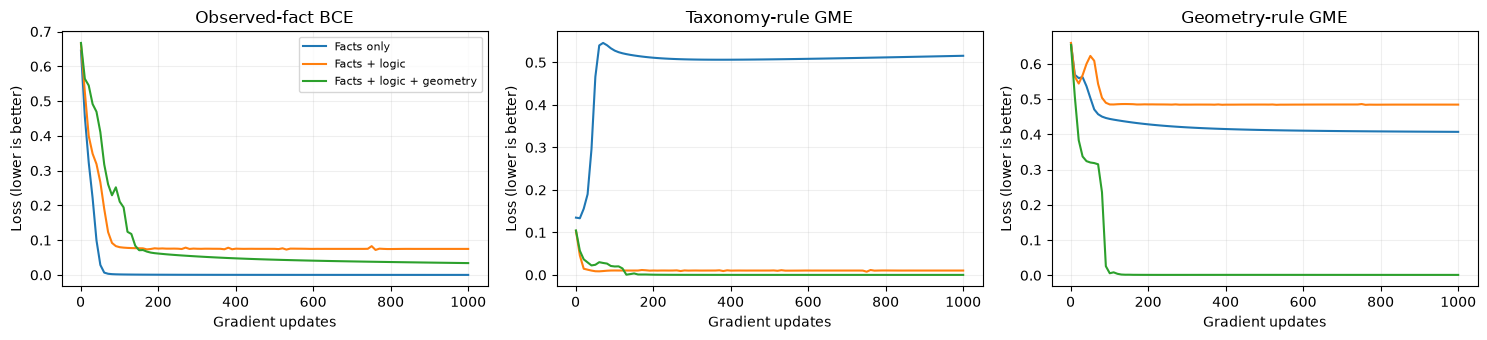

In [8]:
def train(rule_weight=0.0, metric_weight=0.0, steps=1000):
    m=ConceptLTN()
    m.load_state_dict(copy.deepcopy(initial_weights))
    opt=torch.optim.Adam(m.parameters(),lr=0.035)
    hist={'step':[],'facts':[],'rules':[],'metric':[],'total':[]}
    for step in range(steps):
        opt.zero_grad()
        f=fact_loss(m)
        r=rule_loss(m) if rule_weight else None
        g=geometry_loss(m) if metric_weight else None
        loss=f
        if rule_weight: loss=loss+rule_weight*r
        if metric_weight: loss=loss+metric_weight*g
        loss.backward()
        opt.step()
        if step%10==0 or step==steps-1:
            with torch.no_grad():
                hist['step'].append(step+1)
                hist['facts'].append(float(fact_loss(m)))
                hist['rules'].append(float(rule_loss(m)))
                hist['metric'].append(float(geometry_loss(m)))
                hist['total'].append(float(loss))
    return m,hist

models={};histories={}
for name,rw,mw in [('Facts only',0,0),('Facts + logic',2.5,0),
                   ('Facts + logic + geometry',2.5,8.0)]:
    models[name],histories[name]=train(rule_weight=rw,metric_weight=mw)

fig,axes=plt.subplots(1,3,figsize=(15,3.5))
for name,h in histories.items():
    for ax,key in zip(axes,['facts','rules','metric']):
        ax.plot(h['step'],h[key],label=name)
for ax,title in zip(axes,['Observed-fact BCE','Taxonomy-rule GME','Geometry-rule GME']):
    ax.set(title=title,xlabel='Gradient updates',ylabel='Loss (lower is better)')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.tight_layout();plt.show()

## 6 · Visualize the actual learned 2D concept embeddings

Each scatter plot displays the **trained embeddings**, not the hand-drawn taxonomy. The three plots share identical axis limits and equal aspect ratios for a fair geometric comparison. Colors are **only visualization metadata**: no additional family labels enter the training objective.

The mean **within-family distance** measures compactness; the mean **cross-family distance** measures separation. Their ratio is useful to compare runs, but inspect both distances: the ratio alone does not tell us whether *all* pairs are well organized. A rotated or reflected latent space is equally valid, so focus on relative rather than absolute coordinates.

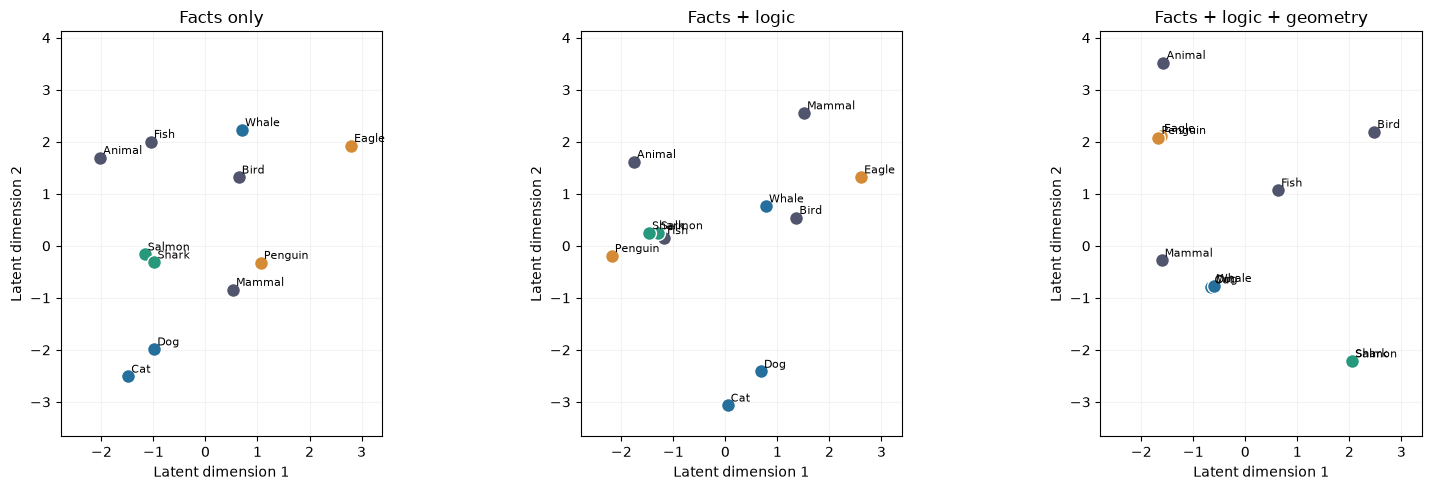

Facts only                 | within-family: 2.71 | cross-family: 3.10 | separation ratio: 1.14x
Facts + logic              | within-family: 2.64 | cross-family: 3.13 | separation ratio: 1.19x
Facts + logic + geometry   | within-family: 0.04 | cross-family: 3.71 | separation ratio: 104.92x


In [9]:
family={'Dog':'Mammal','Cat':'Mammal','Whale':'Mammal',
        'Eagle':'Bird','Penguin':'Bird','Salmon':'Fish','Shark':'Fish'}
colors={'Mammal':'#246f9b','Bird':'#d58b36','Fish':'#26987c'}
allpts=np.concatenate([m.emb.weight.detach().cpu().numpy() for m in models.values()])
minx,miny=allpts.min(0)-.6;maxx,maxy=allpts.max(0)+.6
fig,axes=plt.subplots(1,3,figsize=(16,5))
for ax,(title,m) in zip(axes,models.items()):
    pts=m.emb.weight.detach().cpu().numpy()
    for name in concepts:
        j=ci[name];group=family.get(name,None)
        ax.scatter(*pts[j],s=100,color=colors.get(group,'#51546d'),
                   edgecolors='white',linewidth=1,zorder=2)
        ax.annotate(name,pts[j]+np.array([.06,.07]),fontsize=8)
    ax.set(xlim=(minx,maxx),ylim=(miny,maxy),title=title,
           xlabel='Latent dimension 1',ylabel='Latent dimension 2')
    ax.set_aspect('equal');ax.grid(alpha=.14)
plt.tight_layout();plt.show()

# These groups are deliberately defined only for *evaluation*.
same=[(a,b) for i,a in enumerate(family) for b in list(family)[i+1:]
      if family[a]==family[b]]
different=[(a,b) for i,a in enumerate(family) for b in list(family)[i+1:]
           if family[a]!=family[b]]
for title,m in models.items():
    E=m.emb.weight.detach().cpu().numpy()
    same_dist=np.mean([np.linalg.norm(E[ci[a]]-E[ci[b]]) for a,b in same])
    diff_dist=np.mean([np.linalg.norm(E[ci[a]]-E[ci[b]]) for a,b in different])
    print(f'{title:26s} | within-family: {same_dist:.2f} | '
          f'cross-family: {diff_dist:.2f} | separation ratio: {diff_dist/max(same_dist,1e-8):.2f}x')

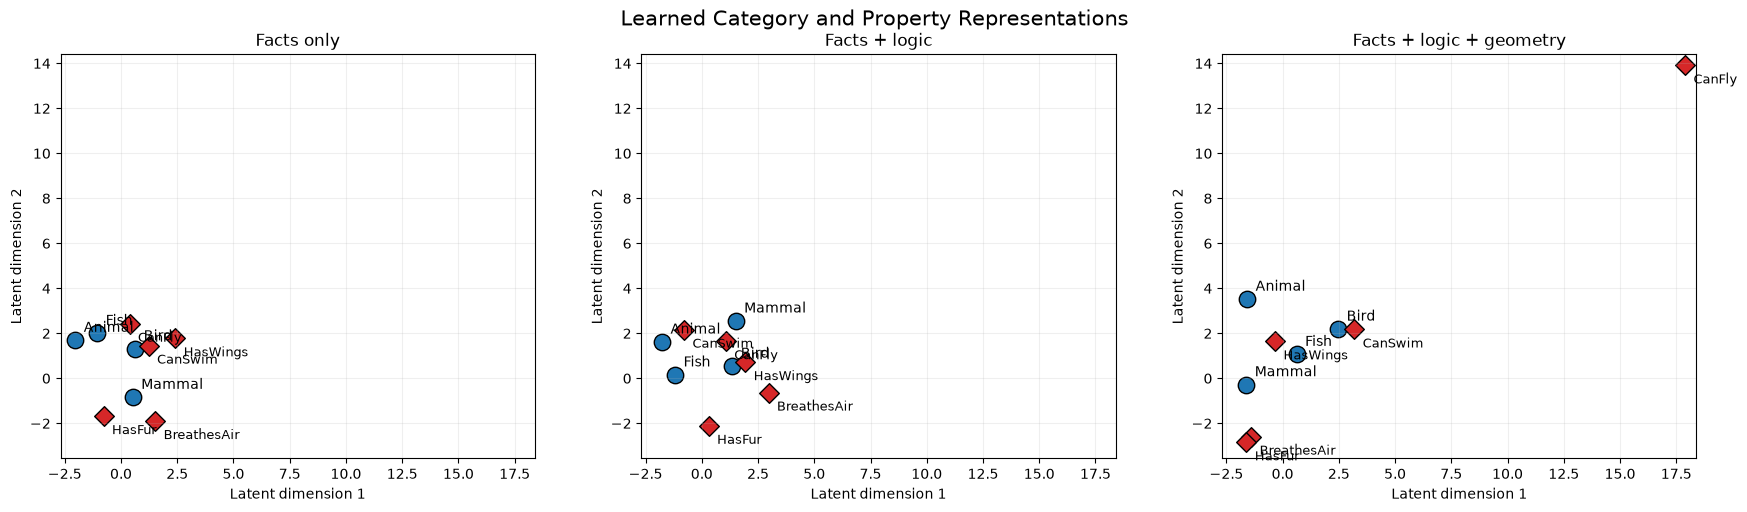

In [10]:
import matplotlib.pyplot as plt
import numpy as np

categories = ["Animal", "Mammal", "Bird", "Fish"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Shared axis limits across all experiments
all_points = np.concatenate([
    np.vstack([
        m.emb.weight.detach().cpu().numpy(),
        m.property_vec.weight.detach().cpu().numpy()
    ])
    for m in models.values()
])

margin = 0.5
xlim = (all_points[:, 0].min() - margin, all_points[:, 0].max() + margin)
ylim = (all_points[:, 1].min() - margin, all_points[:, 1].max() + margin)

for ax, (title, model) in zip(axes, models.items()):

    E = model.emb.weight.detach().cpu().numpy()
    P = model.property_vec.weight.detach().cpu().numpy()

    # Categories: circles
    for category in categories:
        x, y = E[ci[category]]

        ax.scatter(x, y, marker="o", s=140,
                   color="tab:blue", edgecolors="black")

        ax.annotate(category, (x, y), xytext=(6, 6),
                    textcoords="offset points", fontsize=10)

    # Properties: diamonds
    for prop, idx in pi.items():
        x, y = P[idx]

        ax.scatter(x, y, marker="D", s=100,
                   color="tab:red", edgecolors="black")

        ax.annotate(prop, (x, y), xytext=(6, -13),
                    textcoords="offset points", fontsize=9)

    ax.set_title(title)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal")
    ax.set_xlabel("Latent dimension 1")
    ax.set_ylabel("Latent dimension 2")
    ax.grid(alpha=0.2)

plt.suptitle("Learned Category and Property Representations", fontsize=15)
plt.tight_layout()
plt.show()

## 7 · Ask questions that were *not* supervised

This is the main test of **knowledge completion**. We deliberately withhold consequences of the taxonomy and inheritance rules, then evaluate their fuzzy truth degrees **after training**.

For instance:

- $IsA(Dog,Mammal)$ and $IsA(Mammal,Animal)$ support $IsA(Dog,Animal)$.
- $IsA(Penguin,Bird)$ and $HasProperty(Bird,HasWings)$ support $HasProperty(Penguin,HasWings)$.

The positive queries are logically supported by the selected KB rules. The negative test queries are not simply negations of absent facts; their performance is an additional diagnostic of extrapolation. The threshold $0.5$ is a convenient classifier cutoff for demonstration, **not** a formal entailment threshold or calibrated probability guarantee.

In [11]:
@torch.no_grad()
def ask(m,k,a,b):
    x=torch.tensor(ci[a]);y=torch.tensor(ci[b] if k=='IsA' else pi[b])
    return float(m.isa(x,y) if k=='IsA' else m.has(x,y))

names=list(models)
print(f"{'Held-out positive query':38s}"+''.join(f'{n[:22]:>24s}' for n in names))
print('-'*111)
for kind,a,b in heldout_pos:
    txt=f'{kind}({a},{b})'
    print(f'{txt:38s}'+''.join(f'{ask(models[n],kind,a,b):24.2f}' for n in names))
print('\nSUMMARY (threshold 0.5):')
for name,m in models.items():
    pos=np.array([ask(m,*q) for q in heldout_pos]); neg=np.array([ask(m,*q) for q in heldout_neg]);
    print(f'{name:26s} | inferred positives: {(pos>.5).sum():2d}/{len(pos)} | '
          f'negative holdouts: {(neg<.5).sum():2d}/{len(neg)} | '
          f'avg. positive truth: {pos.mean():.3f}')

Held-out positive query                             Facts only           Facts + logic  Facts + logic + geomet
---------------------------------------------------------------------------------------------------------------
IsA(Dog,Animal)                                           1.00                    1.00                    1.00
IsA(Cat,Animal)                                           0.00                    1.00                    1.00
IsA(Whale,Animal)                                         0.20                    1.00                    1.00
IsA(Eagle,Animal)                                         0.00                    1.00                    1.00
IsA(Penguin,Animal)                                       1.00                    1.00                    1.00
IsA(Salmon,Animal)                                        1.00                    1.00                    1.00
IsA(Shark,Animal)                                         1.00                    1.00                    1.00


## 8 · Read out the learned concept–property matrix

Each heatmap cell shows $HasProperty(c,p)\in[0,1]$. Some properties of leaf concepts were never directly supervised, so a high value can reflect **inheritance propagated through logical rules**. Compare the three models row by row; the matrix is a visualization of *predicted fuzzy truth degrees*, not automatically verified biological knowledge.

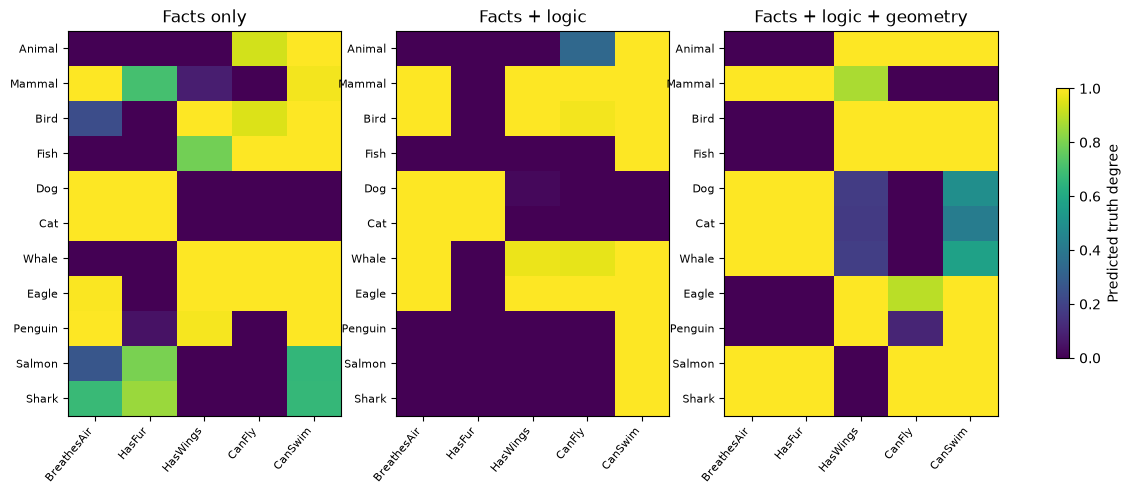

In [12]:
@torch.no_grad()
def matrix(m):
    a=torch.arange(len(concepts))[:,None].expand(-1,len(props))
    b=torch.arange(len(props))[None,:].expand(len(concepts),-1)
    return m.has(a,b).numpy()
fig,axes=plt.subplots(1,3,figsize=(15,5))
for ax,(name,m) in zip(axes,models.items()):
    im=ax.imshow(matrix(m),vmin=0,vmax=1,cmap='viridis',aspect='auto')
    ax.set_title(name)
    ax.set_xticks(range(len(props)),props,rotation=50,ha='right',fontsize=8)
    ax.set_yticks(range(len(concepts)),concepts,fontsize=8)
fig.colorbar(im,ax=axes.tolist(),shrink=.7,label='Predicted truth degree')
plt.show()

## Interpretation, limitations, and exercises

**What changes under each training regime?**

- **Facts only.** The model tries to fit labeled $IsA$ and $HasProperty$ examples. It may still generalize through shared parameters and low-dimensional embeddings, but has no explicit training incentive to respect transitivity and inheritance.
- **Facts + logic.** The model is rewarded for consistent consequences of observed relations. This can improve *withheld-fact completion*. However, correct fuzzy relations need not imply visibly separated clusters.
- **Facts + logic + geometry.** The same supervised facts and logical rules are used, but a distance-based predicate makes family structure geometrically meaningful. These additional constraints are derived from observed taxonomy and disjoint-family assumptions, **not manually annotated `Similar` pairs**.



## Observation and extension — Why do some fish appear to fly?
Inspect the CanFly column of the concept–property heatmaps. The learned predicate may assign a high truth value to $HasProperty(Salmon, CanFly)$ or $HasProperty(Shark, CanFly)$, even though this is biologically incorrect. This is possible because our KB mostly describes positive property inheritance. An unobserved negative fact is not automatically false (open-world reasoning), and the training objective does not enforce a general prohibition on flying fish.

Suggested new logical rule. For this simplified ontology, add the constraint
$$
\forall x\;\bigl(IsA(x, Fish)\rightarrow\neg HasProperty(x,CanFly)\bigr).
$$
In words: every concept classified as a fish must not be assigned the property of flying. This is general logical knowledge, not a new list of supervised negative examples for Salmon and Shark.



## Generalization queries

We now explore how the trained LTN generalizes beyond the observed concepts by querying the learned IsA predicate across the latent space. For each category (Mammal, Bird, and Fish), we visualize the regions where the predicted truth value exceeds a given threshold.

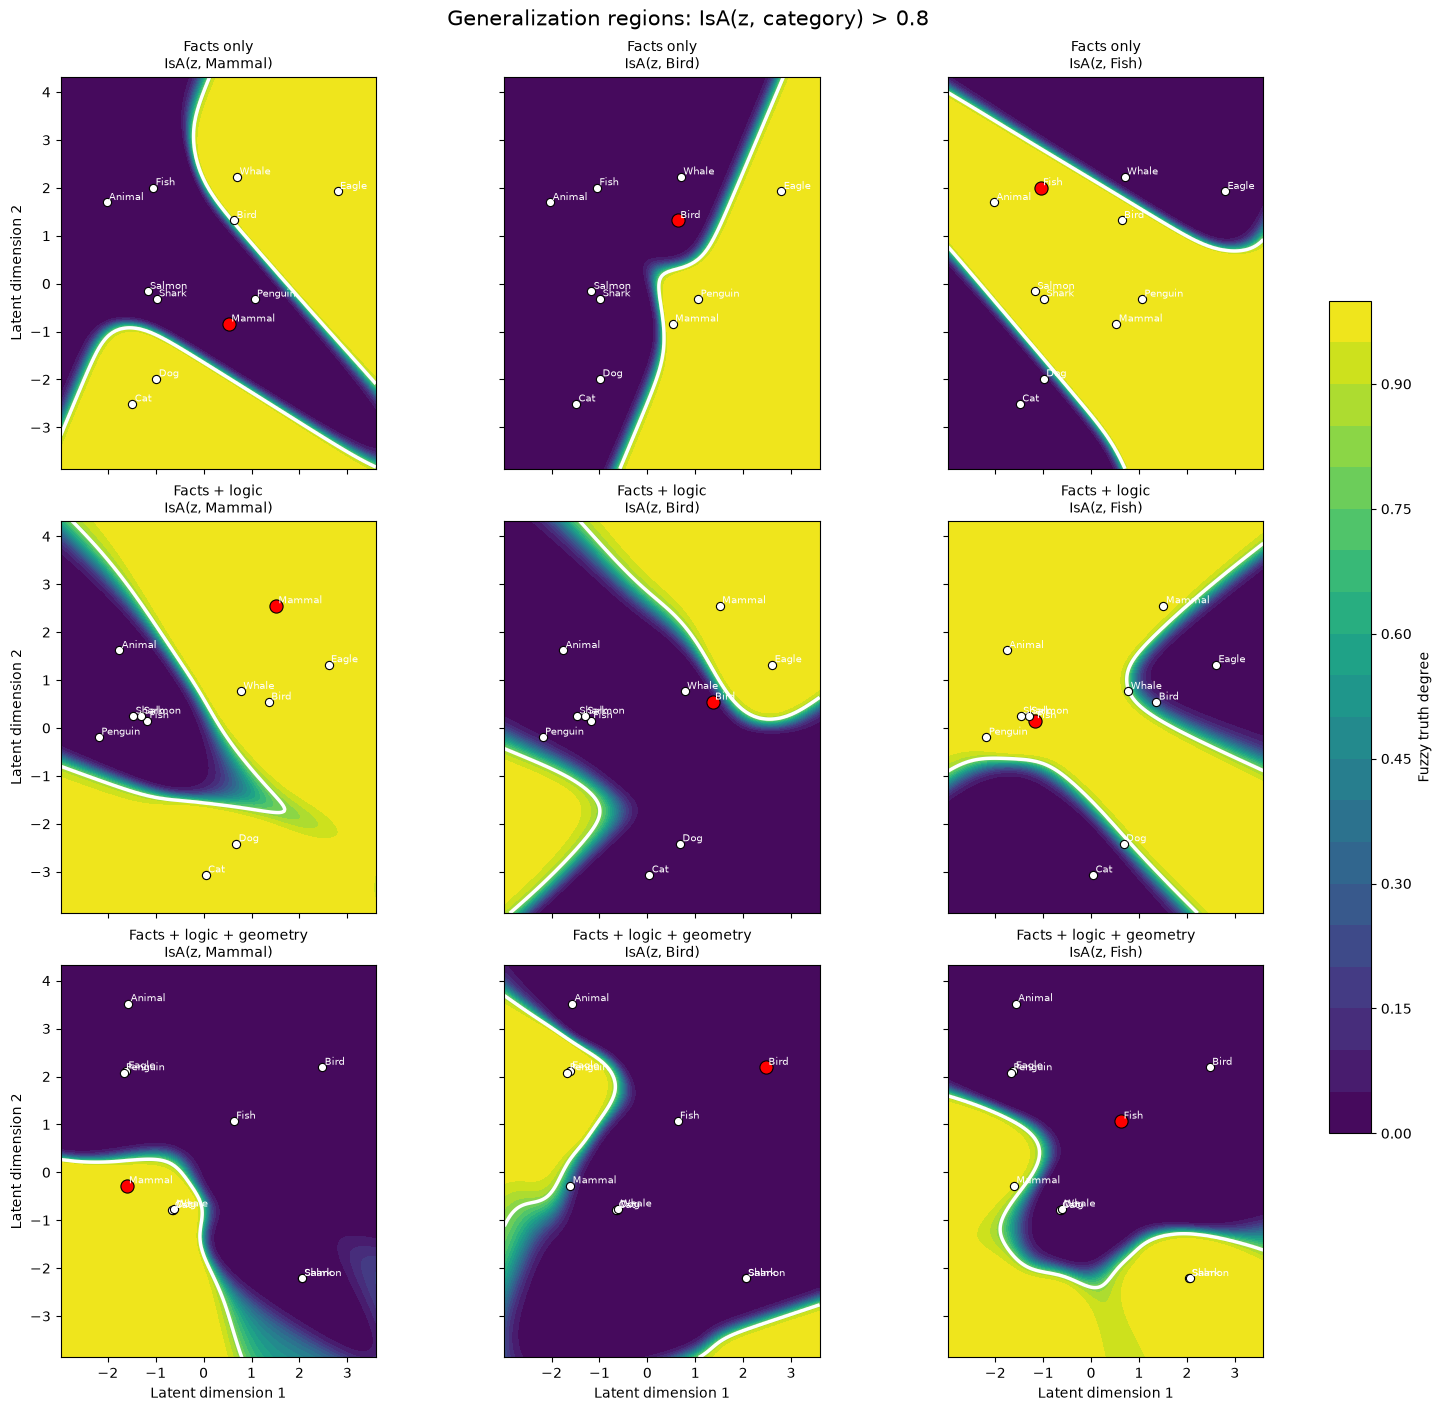

In [13]:

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Generalization query configuration
THRESHOLD = 0.8
GRID_SIZE = 220
CATEGORIES = ["Mammal", "Bird", "Fish"]

category_colors = {
    "Mammal": "#2878B5",
    "Bird": "#E69F36",
    "Fish": "#299D8F"
}

# Shared plotting region across all trained models
all_embeddings = np.concatenate([
    m.emb.weight.detach().cpu().numpy()
    for m in models.values()
])

margin = 0.8
xmin, ymin = all_embeddings.min(axis=0) - margin
xmax, ymax = all_embeddings.max(axis=0) + margin

xx, yy = np.meshgrid(
    np.linspace(xmin, xmax, GRID_SIZE),
    np.linspace(ymin, ymax, GRID_SIZE)
)

grid = torch.tensor(
    np.column_stack([xx.ravel(), yy.ravel()]),
    dtype=torch.float32
)

@torch.no_grad()
def query_latent_space(model, category):
    """Evaluate IsA(z, category) for arbitrary latent points z."""
    model.eval()
    device = model.emb.weight.device

    z = grid.to(device)

    # Learned embedding of the target category
    target = model.emb.weight[ci[category]]
    target = target.unsqueeze(0).expand(len(z), -1)

    # Query the actual learned IsA predicate
    values = model.isa_ground(z, target)

    return values.cpu().numpy().reshape(xx.shape)


fig, axes = plt.subplots(
    3, 3, figsize=(15, 14),
    sharex=True, sharey=True,
    constrained_layout=True
)

for row, (model_name, model) in enumerate(models.items()):

    embeddings = model.emb.weight.detach().cpu().numpy()

    for col, category in enumerate(CATEGORIES):

        ax = axes[row, col]
        scores = query_latent_space(model, category)

        color = category_colors[category]

        # Fuzzy truth values across the latent space
        im = ax.contourf(
            xx, yy, scores,
            levels=np.linspace(0, 1, 21),
            cmap="viridis",
            vmin=0, vmax=1
        )

        # Region satisfying the generalization query
        ax.contour(
            xx, yy, scores,
            levels=[THRESHOLD],
            colors="white",
            linewidths=2.5
        )

        # Learned embeddings of observed concepts
        for name in concepts:
            z = embeddings[ci[name]]

            ax.scatter(
                z[0], z[1],
                s=90 if name == category else 35,
                color="red" if name == category else "white",
                edgecolors="black",
                linewidths=0.8,
                zorder=5
            )

            ax.annotate(
                name, z + np.array([0.05, 0.05]),
                fontsize=7, color="white",
                zorder=6
            )

        ax.set_title(
            f"{model_name}\nIsA(z, {category})",
            fontsize=10
        )
        ax.set_aspect("equal")
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)

        if row == 2:
            ax.set_xlabel("Latent dimension 1")
        if col == 0:
            ax.set_ylabel("Latent dimension 2")

fig.colorbar(
    im, ax=axes,
    shrink=0.65,
    label="Fuzzy truth degree"
)

fig.suptitle(
    f"Generalization regions: IsA(z, category) > {THRESHOLD}",
    fontsize=15
)

plt.show()


In [14]:
model = models["Facts + logic"] # Facts; Facts + logic; Facts + logic + geometry
model.eval()

with torch.no_grad():
    eagle = torch.tensor(ci["Eagle"])
    mammal = torch.tensor(ci["Mammal"])

    truth = model.isa(eagle, mammal).item()

print(f"IsA(Eagle, Mammal) = {truth:.4f}")


IsA(Eagle, Mammal) = 1.0000


## Reasoning: Can Fish Fly?

So far, we have used LTNs for learning and query answering. We now investigate a different task: logical reasoning.

Our goal is to determine whether the knowledge base logically entails that fish can fly:

$$
\mathcal K \models_q HasProperty(Fish,CanFly);?
$$

Unlike query answering, which evaluates a formula under a single learned grounding, reasoning considers different possible groundings that satisfy the knowledge base.

We will compare two approximate reasoning strategies:
1. **Reasoning by optimization:** Train multiple models and evaluate the query in the resulting groundings.
2. **Reasoning by refutation:** Actively search for a grounding that satisfies the knowledge base while making the query false.
We use a satisfaction threshold $q=0.90$. A grounding is considered an approximate model of the knowledge base when its aggregated satisfaction is at least $q$.

Importantly, our knowledge base does not explicitly state that fish can or cannot fly. Missing facts are not automatically interpreted as false.

In [15]:
# Definitions shared by both reasoning experiments
import copy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

Q = 0.90

def fly_query(model):
    """LTNtorch truth degree of HasProperty(Fish, CanFly)."""
    _, Has, _ = operators_for(model)
    fish = ltn.LTNObject(model.concept_vectors(torch.tensor(ci["Fish"])), [])
    flying = ltn.LTNObject(model.property_vectors(torch.tensor(pi["CanFly"])), [])
    return Has(fish, flying).value.reshape(())


def kb_truth_values(model):
    """One truth value per observed fact / selected rule instance."""
    IsA, Has, _ = operators_for(model)

    x, y = grounded(model, [ip_a, ip_b], ["concept", "concept"], "rs_pos_isa")
    pos_isa = IsA(x, y).value

    x, y = grounded(model, [in_a, in_b], ["concept", "concept"], "rs_neg_isa")
    neg_isa = Not(IsA(x, y)).value

    x, p = grounded(model, [hp_a, hp_b], ["concept", "property"], "rs_pos_has")
    pos_has = Has(x, p).value

    x, p = grounded(model, [hn_a, hn_b], ["concept", "property"], "rs_neg_has")
    neg_has = Not(Has(x, p)).value

    x, y, z = grounded(model, [ta, tb, tc], ["concept"] * 3, "rs_trans")
    trans = Implies(And(IsA(x, y), IsA(y, z)), IsA(x, z)).value

    x, y, p = grounded(model, [ia, ib, ip],
                       ["concept", "concept", "property"], "rs_inherit")
    inherit_truth = Implies(And(IsA(x, y), Has(y, p)), Has(x, p)).value

    return torch.cat([t.reshape(-1) for t in
                      (pos_isa, neg_isa, pos_has, neg_has, trans, inherit_truth)])


def kb_satisfaction(model):
    values = kb_truth_values(model)
    return 1.0 - torch.sqrt(torch.mean((1.0 - values).square()) + 1e-12)


with torch.no_grad():
    model = models["Facts + logic"]
    print(f"Trained model: KB satisfaction = {kb_satisfaction(model).item():.4f}")
    print(f"Trained model: CanFly(Fish)    = {fly_query(model).item():.4f}")

Trained model: KB satisfaction = 0.8699
Trained model: CanFly(Fish)    = 0.0023


## Reasoning by Optimization
The first approach searches for different groundings that maximize the satisfaction of the knowledge base:

$$
\theta_i^*\approx\arg\max_\theta Sat(\mathcal K,\theta)
$$

We repeat training from different random initializations and evaluate:

$$
\mathcal G_{\theta_i^*}(HasProperty(Fish,CanFly))
$$

If we find well-satisfying groundings that disagree on the query, this suggests that the knowledge base does not uniquely determine its truth value.

However, observing a high query value in all runs does not establish logical entailment, because optimization may repeatedly converge to similar solutions.


In [16]:
# Experiment 1: several groundings obtained by KB-satisfaction optimization
optimization_results = []
N_RUNS = 6

for run in range(N_RUNS):
    torch.manual_seed(100 + run)
    model = ConceptLTN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.025)

    for step in range(1000):
        optimizer.zero_grad()
        loss = 1.0 - kb_satisfaction(model)
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        sat = kb_satisfaction(model).item()
        truth = fly_query(model).item()
    optimization_results.append((sat, truth))
    print(f"Run {run+1}: Sat(KB)={sat:.3f}, CanFly(Fish)={truth:.3f}, "
          f"qualifies={sat >= Q}")

qualified = [(s, t) for s, t in optimization_results if s >= Q]
print(f"\nQualifying groundings: {len(qualified)}/{N_RUNS}")
if qualified:
    print("Counterexample found among these runs:", any(t < Q for s, t in qualified))
else:
    print("No run reached the satisfaction threshold; result inconclusive.")

Run 1: Sat(KB)=0.863, CanFly(Fish)=0.000, qualifies=False
Run 2: Sat(KB)=0.911, CanFly(Fish)=0.655, qualifies=True
Run 3: Sat(KB)=1.000, CanFly(Fish)=0.961, qualifies=True
Run 4: Sat(KB)=1.000, CanFly(Fish)=0.558, qualifies=True
Run 5: Sat(KB)=1.000, CanFly(Fish)=1.000, qualifies=True
Run 6: Sat(KB)=1.000, CanFly(Fish)=0.008, qualifies=True

Qualifying groundings: 5/6
Counterexample found among these runs: True



## Reasoning by Refutation

Instead of evaluating the query on models obtained by maximizing knowledge-base satisfaction, we now **actively search for a counterexample**.

Our goal is to determine whether:

$$
\mathcal K \models_q \phi
$$

where $\phi = HasProperty(Fish, CanFly)$.

To disprove this entailment, we search for a grounding $\theta$ such that:

$$
Sat(\mathcal K,\theta)\geq q
$$

but simultaneously:

$$
\mathcal G_\theta(\phi)<q.
$$

In other words, we seek a model that sufficiently satisfies the knowledge base while **falsifying the proposed conclusion**.

#### Soft penalty formulation

Rather than enforcing the knowledge-base satisfaction threshold as a hard constraint, we use the **soft penalty proposed by Badreddine et al. (2022)**:

$$
\mathcal L_{\mathrm{ref}}(\theta)
=
\mathcal G_\theta(\phi)
+
\operatorname{Penalty}(Sat(\mathcal K,\theta))
$$

where:

$$
\operatorname{Penalty}(s)=
\begin{cases}
\beta(q-s), & s\leq q,\\[4pt]
\alpha\left(e^{\frac{\beta}{\alpha}(q-s)}-1\right), & s>q.
\end{cases}
$$

Here, $\alpha>0$ and $\beta>0$ are hyperparameters controlling the penalty.

- **When $s<q$:** the penalty grows linearly, discouraging groundings that do not sufficiently satisfy the knowledge base.
- **When $s>q$:** the penalty becomes negative and smoothly approaches $-\alpha$, encouraging satisfaction while providing diminishing gradients.
- **Query minimization:** the first term pushes the query's truth value towards zero, encouraging the discovery of a counterexample.

The penalty can be implemented directly using PyTorch's `F.elu` function.

#### Interpreting the result

If optimization finds a grounding satisfying both:

$$
Sat(\mathcal K,\theta)\geq q
\qquad\text{and}\qquad
\mathcal G_\theta(\phi)<q,
$$

we have found a counterexample, establishing that the query is **not entailed** under the considered semantics:

$$
\mathcal K\not\models_q HasProperty(Fish,CanFly)
$$

Conversely, **failure to find a counterexample does not prove entailment**, since gradient-based optimization may fail to explore some satisfying groundings.

Reasoning by refutation differs from ordinary query answering because it searches for alternative groundings that challenge a proposed logical consequence, rather than simply evaluating the query under an already learned model.

Restart 1: COUNTEREXAMPLE at step 1500: Sat(KB)=0.9111, CanFly(Fish)=0.0000
Restart 2: COUNTEREXAMPLE at step 1500: Sat(KB)=0.9111, CanFly(Fish)=0.0000
Restart 3: COUNTEREXAMPLE at step 1500: Sat(KB)=0.9111, CanFly(Fish)=0.0000


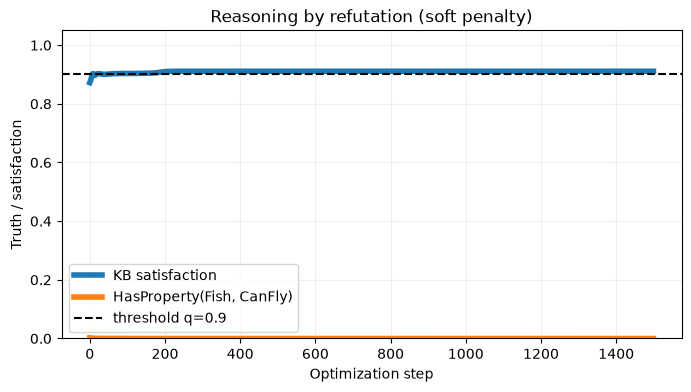

In [19]:
# Experiment 2: soft-penalty reasoning by refutation

def soft_penalty(sat, q=Q, alpha=0.05, beta=5.0):
    return F.elu(beta * (q - sat), alpha=alpha)


def refutation_run(seed=0, steps=1500, lr=0.005, alpha=0.05, beta=5.0):
    torch.manual_seed(200 + seed)
    model = copy.deepcopy(models["Facts + logic"])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"sat": [], "query": []}
    best = None

    for step in range(steps):
        optimizer.zero_grad()
        sat = kb_satisfaction(model)
        truth = fly_query(model)
        loss = truth + soft_penalty(sat, q=Q, alpha=alpha, beta=beta)
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            s = kb_satisfaction(model).item()
            t = fly_query(model).item()
            history["sat"].append(s)
            history["query"].append(t)
            if s >= Q and t < Q and (best is None or t < best["query"]):
                best = {"sat": s, "query": t,
                        "state": copy.deepcopy(model.state_dict()),
                        "step": step + 1}

    return model, history, best


refutation_models = []
for seed in range(3):
    m, h, best = refutation_run(seed=seed)
    refutation_models.append((m, h, best))
    if best is None:
        print(f"Restart {seed+1}: no valid counterexample found")
    else:
        print(f"Restart {seed+1}: COUNTEREXAMPLE at step {best['step']}: "
              f"Sat(KB)={best['sat']:.4f}, CanFly(Fish)={best['query']:.4f}")

# Show optimization trajectory for the first restart
_, history, _ = refutation_models[0]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["sat"], label="KB satisfaction", linewidth=4)
ax.plot(history["query"], label="HasProperty(Fish, CanFly)", linewidth=4)
ax.axhline(Q, color="black", linestyle="--", label=f"threshold q={Q}")
ax.set(xlabel="Optimization step", ylabel="Truth / satisfaction",
       ylim=(0, 1.05), title="Reasoning by refutation (soft penalty)")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

**Exercise:** Use reasoning by refutation to investigate whether the knowledge base entails that dogs are animals, i.e., $(\mathcal K \models_q IsA(Dog, Animal))$. Can you find a counterexample that satisfies the knowledge base while falsifying the query?